# Does "reorders per member" reward what the head of Retail-Plus needs from the tier?

Week 4, Monday, the TA-led practice lab. The method of the morning, moved to Kalpa Retail,
the programme's fictional client: Kalpa and its people are invented, and the data are
synthetic.

**The situation.** The head of Retail-Plus, who owns Kalpa's paid membership tier, wants a
growth number for the tier: reorders placed per member. Until 9 September 2026 a member
reordered by tapping the app's Reorder button; from 10 to 30 September 2026 the app's
auto-reorder feature placed reorders on members' behalf. The comparison is the three weeks
before that, 20 August to 9 September 2026, and both windows sit after the monsoon sale's
last day, 19 August.

**The data.**

| Table | Columns | Rows |
|---|---|---|
| `kalpa_members` | `customer_id`, `tier`, `member_since` (the day the membership started) | the tier's 120 members, the same table Thursday's lab reads |
| `kalpa_app_reorders` | `reorder_id`, `customer_id`, `placed_ts`, `value_rs` (the placement's booked value, whatever happened to it), `auto` (True when the app placed it on its own), `status`, `order_id` (the order in Kalpa's warehouse that the placement became, blank if none) | one row per reorder placement, 20 August to 30 September 2026 |

A placement's `status` is delivered, returned or cancelled, merged (its items joined a
basket the member already had open, so it never became an order of its own) or pending
(still waiting). From 10 September the app orders in the Week 2 warehouse are members' own
orders through the normal checkout, and they are not in `kalpa_app_reorders`.

**Who needs the answer.** The head of Retail-Plus, who is about to take "reorders per
member" to the growth review, the meeting where each team's numbers are judged, as the
tier's number. If it can rise while the tier earns less, the review rewards the app for
placing orders nobody receives.

**The questions on the way.**

1. What does the table hold, before anything is counted?
2. What do seven members' rows say, counted by hand?
3. What do reorders placed per member and booked value per member do across the two windows?
4. Which reorders are these, and what happened to them?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

members = pd.read_csv("../data/C2_W04_D01_kalpa_members_STUDENT.csv")
reorders = pd.read_csv("../data/C2_W04_D01_kalpa_app_reorders_STUDENT.csv")
reorders["day"] = reorders["placed_ts"].str[:10]
print(f"{len(members)} Retail-Plus members; {len(reorders)} reorder placements from {reorders.day.min()} to {reorders.day.max()}")

120 Retail-Plus members; 89 reorder placements from 2026-08-21 to 2026-09-30


## What does the table hold, before anything is counted?

This cell draws three plain views of the whole table, both windows together: what a
placement is worth, how many placements each member made, and how many members the tier
held on each day of the two windows. It also keeps the members who had joined by 19 August
as `base`, the members the per-member comparison counts.

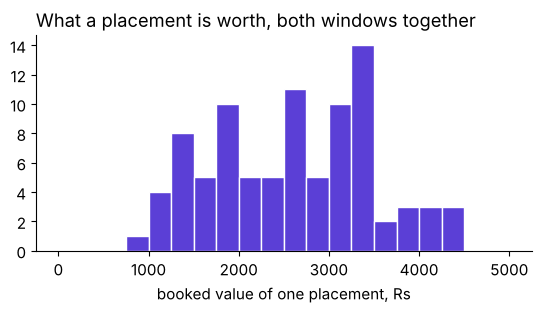

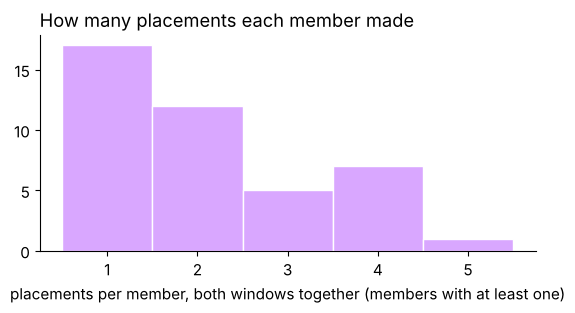

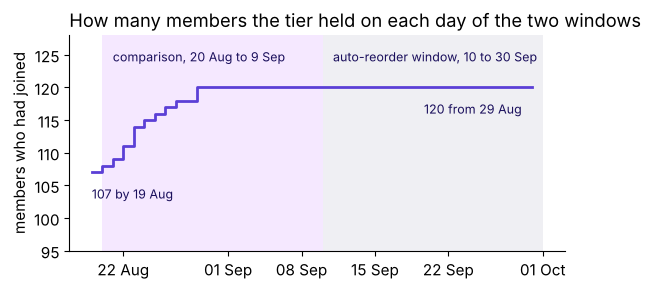

107 members had joined by 19 August


In [2]:
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.hist(reorders["value_rs"], bins=range(0, 5001, 250), color=VIOLET, edgecolor="white")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("booked value of one placement, Rs")
ax.set_title("What a placement is worth, both windows together", loc="left")
plt.show()
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.hist(reorders.groupby("customer_id").size(), bins=range(1, 7), color=LAV, edgecolor="white", align="left")
ax.set_xlabel("placements per member, both windows together (members with at least one)")
ax.set_title("How many placements each member made", loc="left")
plt.show()
days = pd.date_range("2026-08-19", "2026-09-30")
joined = [(members["member_since"] <= d.strftime("%Y-%m-%d")).sum() for d in days]
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.axvspan(pd.Timestamp("2026-08-20"), pd.Timestamp("2026-09-10"), color=LAV, alpha=0.25, lw=0)
ax.axvspan(pd.Timestamp("2026-09-10"), pd.Timestamp("2026-10-01"), color=MUTED, alpha=0.10, lw=0)
ax.step(days, joined, where="post", color=VIOLET, lw=2)
ax.text(pd.Timestamp("2026-08-21"), 124, "comparison, 20 Aug to 9 Sep", color=INK, fontsize=9)
ax.text(pd.Timestamp("2026-09-11"), 124, "auto-reorder window, 10 to 30 Sep", color=INK, fontsize=9)
ax.text(pd.Timestamp("2026-08-19"), joined[0] - 4, f"{joined[0]} by 19 Aug", color=INK, fontsize=9)
ax.text(pd.Timestamp("2026-09-29"), joined[-1] - 4, f"{joined[-1]} from 29 Aug", color=INK, fontsize=9, ha="right")
ax.set_ylim(95, 128)
ax.set_ylabel("members who had joined")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("How many members the tier held on each day of the two windows", loc="left")
plt.show()
base = members.loc[members["member_since"] <= "2026-08-19", "customer_id"]
print(len(base), "members had joined by 19 August")

## What do seven members' rows say, counted by hand?

Your TA hands out a sheet with seven members' placements and booked values in the two
windows: C-0152, C-0184, C-0211, C-0215, C-0224, C-0240 and C-0264, all seven in the tier
for the whole of both windows. Before the ratio code runs, add up each window's placements
and booked value for the seven, divide by seven, and write the two ratios (window over
comparison) on the sheet. The seven cancels out of each ratio, so the per-member form gives
the same answer as the totals; it is the form the head of Retail-Plus reports. Working
without the sheet, type these two lines into the empty cell below first and run them, where
False is the comparison window and True the auto-reorder window:

```python
seven = ["C-0152", "C-0184", "C-0211", "C-0215", "C-0224", "C-0240", "C-0264"]
print(reorders[reorders["customer_id"].isin(seven)].groupby(["customer_id", reorders["day"] >= "2026-09-10"])["value_rs"].agg(["size", "sum"]))
```

## What do reorders placed per member and booked value per member do across the two windows?

The per-member comparison counts only the 107 members in `base`, who had joined by 19
August, because a member who joined later had fewer of the comparison window's days to
reorder in: one who joined on 25 August had 16 of its 21.

**Predict before you run.** From the comparison window to the auto-reorder window, reorders
placed per member a) fell; b) held about level; c) rose by up to a third; d) rose by more than
a third. And booked value per member a) fell; b) held about level; c) rose by up to a third;
d) rose by more than a third.

**Your turn.** Then type these lines into the same empty cell and run it again:

```python
comparison = reorders[reorders["day"].between("2026-08-20", "2026-09-09") & reorders["customer_id"].isin(base)]
window = reorders[reorders["day"].between("2026-09-10", "2026-09-30") & reorders["customer_id"].isin(base)]
placed = (len(window) / len(base)) / (len(comparison) / len(base))
booked = (window["value_rs"].sum() / len(base)) / (comparison["value_rs"].sum() / len(base))
print(round(placed, 2), round(booked, 2))
```

`.between(start, end)` keeps the days from the first date to the second, both included, and
`.isin(base)` keeps the 107 members' rows.

## Which reorders are these, and what happened to them?

**Your turn.** Type these lines into the empty cell below and run it, then say in one
sentence to your neighbour what the window's placements were and what became of them. The
third line counts the placements in each window that became an order in the warehouse:

```python
print(window.groupby(["auto", "status"]).size())
print(comparison.groupby(["auto", "status"]).size())
print(window["order_id"].notna().sum(), comparison["order_id"].notna().sum())
print(window["value_rs"].mean(), comparison["value_rs"].mean())
```

This cell checks the table itself, so a wrong count in your cells cannot come from a broken file.

In [3]:
since = reorders["customer_id"].map(members.set_index("customer_id")["member_since"])
check("120 Retail-Plus members, one row each", len(members) == 120 and members["customer_id"].is_unique)
check("every placement has a unique id", reorders["reorder_id"].is_unique)
check("every placement falls between 20 August and 30 September", reorders["day"].between("2026-08-20", "2026-09-30").all())
check("every status is delivered, returned, cancelled, merged or pending",
      reorders["status"].isin(["delivered", "returned", "cancelled", "merged", "pending"]).all())
check("every booked value is positive", (reorders["value_rs"] > 0).all())
check("every placement belongs to a member and falls on or after the day the member joined",
      since.notna().all() and (reorders["day"] >= since).all())
check("no warehouse order appears twice", reorders["order_id"].dropna().is_unique)

PASS 120 Retail-Plus members, one row each
PASS every placement has a unique id
PASS every placement falls between 20 August and 30 September
PASS every status is delivered, returned, cancelled, merged or pending
PASS every booked value is positive
PASS every placement belongs to a member and falls on or after the day the member joined
PASS no warehouse order appears twice


## What does the lab hand on?

Write on the TA's sheet: your two ratios from the hand count and from the full table, the one
sentence on what the window's placements were and what became of them, and which line of a
complete definition would have stopped "reorders per member" being paid for that.

**The check a senior analyst runs.** The baseline (the comparison window), the denominator
(the 107 members in the tier for the whole of both windows), the evidence that the thing the
number stands for moved (booked value and what became an order), and a second way to the
same answer (the hand count against the full table).

The unguided exercise that follows writes the growth plan's own north star, delivered orders
per active customer per month, on the same seven-line template as the morning's.